# Final deliverable: delivery route optimization (CVRP and CVRPTW)

**CesiCDP for the ADEME Smart Multimodal Mobility call.** Team: Pablo, Dag, Farida.

*One depot, identical trucks, customers with a demand and a time window, travel times that depend
on the hour: which truck serves which customers, in which order, so that the total route duration
is minimal?* The problem is NP-hard (section 2); the exact model solves it up to 7 or 8 customers
with traffic and up to 100 customers on easy instances without traffic (section 4). Of three
metaheuristics compared on 50 Solomon test instances at equal time (6 more for tuning), **GRASP-ILS** is the best, with
a mean gap of 1.16 % to the best known solutions (section 8). Scaled to 1 000 customers it stays
the best with time windows, but on real road networks without windows and at 10 000 customers
Tabu Search wins; section 9 gives our choice per scenario.

| Section | Content | Author |
| --- | --- | --- |
| 1 to 4 | data, complexity, ILP, exact approach | Pablo |
| 5 to 7 | chosen metaheuristic, implementation, test cases | Farida (GRASP), written up by Pablo |
| 8 | experimental study of Tabu Search (Pablo), SA (Dag), GRASP-ILS (Farida) | Pablo |
| 9 | scale, real road networks, night, sensitivity, recommendation | Pablo, with each author's runs |
| 10, 11 | limitations, references | all |

Run from the repository root or `notebooks/`, after `pip install -e ".[dev]"`; sections 4 and 8 read
the CSV files written by `experiments/exact_study.py` (about 30 min) and
`experiments/solomon_study.py` (about 1.5 h on 7 cores); the other cells take about 1 min.

## Contents

| | Section | What it answers |
| --- | --- | --- |
| 1 | [Data formalization](#s1) | which data the problem reads, and what the model decides |
| 2 | [Complexity](#s2) | why no fast exact algorithm is expected (NP-hard) |
| 3 | [Complete ILP](#s3) | the model, constraint by constraint, and the code that solves it |
| 4 | [Exact approach in practice](#s4) | up to which size the ILP proves the optimum |
| 5 | [Chosen metaheuristic: GRASP-ILS](#s5) | how the chosen method works, and the two others |
| 6 | [Implementation](#s6) | the method running on three instances |
| 7 | [Test cases](#s7) | how we know the code is right |
| 8 | [Experimental study](#s8): [tuning](#s81), [results](#s82), [tests](#s83) | which method is best, with statistics |
| 9 | [Scale, real networks, night](#s9): [1 000](#s91), [10 000](#s92), [cities](#s93), [night](#s94), [parameters](#s95), [recommendation](#s96) | where each method breaks, and which to use when |
| 10 | [Limitations and improvements](#s10) | what is not covered yet |
| 11 | [References](#s11) | sources |
| A | [Glossary of symbols](#sA) | every symbol of the notebook in one table |

<a id="s1"></a>
## 1. Data formalization

The road network is reduced to a **complete directed graph** on the depot and the customers; the
time of a trip $i \to j$ is the fastest path in the network, computed once. The depot appears
twice, node $0$ (departure) and node $n + 1$ (return), so each truck has a departure and a return
time. All times are minutes after midnight.

| Symbol | Meaning | Unit |
| --- | --- | --- |
| $V^+ = \{1, \dots, n\}$ | customers | |
| $V = \{0\} \cup V^+ \cup \{n+1\}$ | nodes; $0$ and $n+1$ are the depot | |
| $A$ | trips: depot to customer, customer to customer, customer to depot, and $0 \to n+1$ (truck not used) | |
| $\mathcal{K} = \{1, \dots, K\}$ | identical trucks | |
| $\mathcal{H} = \{0, \dots, 23\}$ | hours of the day | |
| $Q$ | capacity of a truck | units |
| $q_i$ | demand of customer $i$ ($q_i \le Q$) | units |
| $[e_i, l_i]$ | time window: service must **start** in it | min |
| $s_i$ | service time at customer $i$ ($s_0 = 0$) | min |
| $[e_0, l_0]$ | working day of the depot | min |
| $c_{ij}$ | travel time from $i$ to $j$ on empty roads | min |
| $\rho_h$ | traffic intensity of hour $h$ ($\rho_h \ge 1$) | |
| $c_{ij}^h = \rho_h \, c_{ij}$ | **traffic matrix**: travel time when leaving $i$ during hour $h$ | min |

The $\rho_h$ values (peaks 1.75 to 1.80 from 7:00 to 9:00 and from 17:00 to 19:00, 1.00 at night)
are assumptions of notebook 01, to be replaced by measured data. The model only reads numbers from
the matrix, so measured values change no equation.

**Decision variables**

| Variable | Domain | Meaning |
| --- | --- | --- |
| $x_{ij}^k$ | $\{0, 1\}$ | truck $k$ drives directly from $i$ to $j$ |
| $y_{ih}$, $y_{0h}^k$ | $\{0, 1\}$ | the truck leaves customer $i$ (the depot, for truck $k$) during hour $h$ |
| $t_0^k$, $t_{n+1}^k$ | $\ge 0$, min | truck $k$ leaves the depot, is back |
| $a_i$, $w_i$, $t_i$ | $\ge 0$, min | arrival, waiting and service start at customer $i$ |

The travel time is fixed by the hour of departure, so a later departure may arrive earlier (the
first in, first out property is not guaranteed): an accepted simplification.

**Benchmark data.** The Solomon instances (56 files, 100 customers, PyVRP/VRPLIB copy) give
$c_{ij}$ as Euclidean distances truncated to one decimal, the convention of their best known
values, and no traffic ($\rho_h = 1$).

<a id="s2"></a>
## 2. Complexity

**Decision version (DEC).** Given an instance and a number $B$, is there a feasible plan of total
route duration at most $B$?

**DEC is in NP.** A certificate is the list of routes with each truck's departure time (a rational
of polynomial size: an optimal departure can be taken at a breakpoint of the piecewise linear
schedule). Checking
that every customer appears once, that each load is at most $Q$, and computing the schedule along
each route (one matrix read, one comparison per visit) takes $O(n + K)$ operations; comparing the
total with $B$ is one more.

**Hamiltonian cycle reduces to DEC.** Let $G = (U, E)$ be a graph with $U = \{u_0, \dots, u_m\}$,
$m \ge 2$. Build in $O(m^2)$ the instance: depot $u_0$, customers $u_1, \dots, u_m$, $K = 1$,
$q_i = 1$, $Q = m$, $s_i = 0$, every window equal to the whole day, $\rho_h = 1$ for every $h$,
$c_{ij} = 1/(m+1)$ minute if $\{u_i, u_j\} \in E$ and $c_{ij} = 2/(m+1)$ otherwise, and $B = 1$
(so every plan fits in the day whatever $m$).

- If $G$ has a Hamiltonian cycle, start it at $u_0$: the truck follows it, each of its $m + 1$
  trips takes $1/(m+1)$, no window makes it wait, so the duration is $1 \le B$.
- If a plan has duration at most $1$: the single truck visits the $m$ customers once each and
  returns, so its route is a cycle through all $m + 1$ nodes made of $m + 1$ trips. Each trip takes
  at least $1/(m+1)$, so all of them take exactly $1/(m+1)$, and each one is an edge of $G$: the
  route is a Hamiltonian cycle of $G$.

Hamiltonian cycle is NP-complete (Karp, 1972), so DEC is **NP-complete** and the optimization
problem is **NP-hard**. The instance built uses only the special case $K = 1$, $\rho_h = 1$, wide
windows, which is the travelling salesman problem: capacity, windows and traffic add constraints
to a problem that is already hard. Capacity alone is hard too: deciding whether $K$ trucks can
carry the demands is bin packing (Garey and Johnson, 1979).

**Consequence.** No polynomial exact algorithm is expected. Section 4 measures where the exact ILP
stops being usable; sections 5 to 8 use metaheuristics for the realistic sizes.

<a id="s3"></a>
## 3. Complete ILP

$$
\begin{aligned}
\min \quad & z = \sum_{k \in \mathcal{K}} \big( t_{n+1}^k - t_0^k \big) \\[4pt]
\text{s.t.} \quad
& \sum_{k} \sum_{j : (i, j) \in A} x_{ij}^k = 1 && \forall i \in V^+ && \text{(1) each customer served once}\\
& \sum_{j} x_{0j}^k = 1, \quad \sum_{i} x_{i, n+1}^k = 1 && \forall k && \text{(2), (4) each truck leaves and returns}\\
& \sum_{i} x_{ij}^k = \sum_{i} x_{ji}^k && \forall j \in V^+,\ k && \text{(3) a truck that enters leaves}\\
& \sum_{i \in V^+} q_i \sum_{j} x_{ij}^k \le Q && \forall k && \text{(5) capacity}\\
& \sum_h y_{ih} = 1, \quad \sum_h 60h\, y_{ih} \le t_i + s_i \le \sum_h 60(h+1)\, y_{ih} && \forall i \in V^+ && \text{(6), (7) departure hour}\\
& \sum_h y_{0h}^k = 1, \quad \sum_h 60h\, y_{0h}^k \le t_0^k \le \sum_h 60(h+1)\, y_{0h}^k && \forall k && \text{(6), (7) at the depot}\\
& \Big\lvert\, a_j^k - t_i^k - s_i - \sum_h c_{ij}^h\, y_{ih}^k \,\Big\rvert \le M (1 - x_{ij}^k) && \forall (i, j) \in A,\ k && \text{(8) arrival with traffic}\\
& t_i = a_i + w_i, \quad e_i \le t_i \le l_i && \forall i \in V^+ && \text{(9), (10) wait, then serve}\\
& t_0^k \ge e_0, \quad t_{n+1}^k \le l_0 && \forall k && \text{(10) working day}\\
& x,\ y \in \{0, 1\}, \quad a,\ w,\ t \ge 0 && && \text{(11)}
\end{aligned}
$$

Shorthands in (8): $t_i^k$ is $t_i$ at a customer and $t_0^k$ at the depot, $a_j^k$ is $a_j$ at a
customer and $t_{n+1}^k$ at the return, $y_{ih}^k$ is $y_{ih}$ at a customer and $y_{0h}^k$ at the
depot. $M = 2880$ (two days) exceeds every possible value of
$\lvert a_j - t_i - s_i - c_{ij}^h \rvert$ within a working day, so (8) is inactive when
$x_{ij}^k = 0$. The absolute value stands for two linear inequalities; since $c_{ij}^h + s_i > 0$,
times increase along a route and (8) also forbids subtours. $w_i$ is kept so that the waiting
appears in the solution; it could be replaced by $t_i \ge a_i$. Every line is linear: the model is a mixed
integer linear program with $K \lvert A \rvert$ variables $x$, $24 (n + K)$ variables $y$ and
$3n + 2K$ real variables.

**Reading the model line by line.** A sum $\sum_{k}$ adds over the trucks, $\sum_{j : (i,j) \in A}$
over the allowed next stops after $i$, $\sum_h$ over the hours of the day; $\forall$ means the line
is written once for each element of the set.

| Line | In words | Why it is needed |
| --- | --- | --- |
| objective | add, over the trucks, return time minus departure time | the brief asks for the minimum total route duration; one component |
| (1) | for each customer, exactly one arc leaves it, over all trucks | every customer is served, once, by one truck |
| (2) | each truck takes exactly one arc out of the depot (possibly $0 \to n+1$, unused) | each truck has one route; fewer than $K$ trucks are allowed |
| (3) | for each customer and truck, arcs in = arcs out | a truck that reaches a customer leaves it: routes are paths |
| (4) | each truck takes exactly one arc into the return depot | every route ends at the depot |
| (5) | the demands of the customers truck $k$ leaves from add up to at most $Q$ | the load of a truck, full at departure, fits its capacity |
| (6) | exactly one departure hour per stop | picks which value of the traffic matrix applies |
| (7) | the departure time lies inside that hour | ties the hour $h$ to the clock time |
| (8) | if truck $k$ drives $i \to j$, arrival at $j$ = departure from $i$ + travel time of the departure hour | traffic enters the times; switched off by $M$ when the arc is unused; forbids subtours |
| (9) | service start = arrival + waiting | a truck may wait for a window to open |
| (10) | service starts inside the window; trucks work inside the day | time windows and working day |
| (11) | $x, y$ binary, times non-negative | domains |

**What the code solves** (`src/cvrp/ilp.py`)

| Function | Model | Used for |
| --- | --- | --- |
| `solve_tdvrptw` | the model above, constraints (1) to (11) | exact optimum with traffic, small $n$ |
| `solve_cvrptw` | benchmark variant: $\rho_h = 1$, two-index $x_{ij}$, objective replaced by total distance $\sum c_{ij} x_{ij}$ | the Solomon benchmark |
| `solve_cvrp_flow`, `_rcc`, `_mtz` | the same variant without windows | CVRP, lower bounds |

The Solomon best known values minimize **total distance** with travel time equal to distance and
no traffic. With $\rho_h = 1$ our objective equals that distance plus the service times (a
constant) plus the waiting, so the benchmark variant optimizes our objective without its waiting
term: it measures the routing part of the model, the only one for which published optima exist. The metaheuristics take the route cost as a function, so the
same search runs on the duration with traffic (`cvrp.tabu.duration_cost`, GRASP
`objective="duration"`).

The cell below solves the model on the toy instance of notebook 01 and compares it with an
enumeration of every partition, visiting order and departure time (0.25 min steps).

In [1]:
import itertools
import sys
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "experiments"))  # used from section 6 on

from cvrp import Instance
from cvrp.ilp import solve_tdvrptw
from cvrp.tabu import RHO

coords = np.array([[0, 0], [1, 0], [2, 0], [0, 1], [0, 2], [-1, 0], [0, -1]], dtype=float)
q = np.array([0, 4, 4, 3, 3, 5, 5])
e = np.array([360, 480, 480, 420, 540, 600, 600], dtype=float)
l = np.array([1200, 540, 660, 480, 600, 840, 840], dtype=float)
s = np.array([0, 10, 10, 10, 10, 10, 10], dtype=float)
c = 10 * np.linalg.norm(coords[:, None] - coords[None], axis=2)
toy = Instance("toy", coords, q, capacity=10, num_vehicles=3, ready_times=e, due_times=l,
               service_times=s, dist=c)
res = solve_tdvrptw(toy, RHO, time_limit=60)


def duration(route, t0):
    # Route duration leaving the depot at t0, or None if a window is missed.
    i, t = 0, t0
    for j in route + [0]:
        leave = t + s[i]
        arrive = leave + RHO[int(leave // 60)] * c[i, j]
        if j == 0:
            return arrive - t0 if arrive <= l[0] else None
        t = max(arrive, e[j])
        if t > l[j]:
            return None
        i = j


@lru_cache(None)
def best_route(customers):
    if q[list(customers)].sum() > toy.capacity:
        return np.inf
    return min((d for p in itertools.permutations(customers) for t0 in np.arange(e[0], l[0], 0.25)
                if (d := duration(list(p), t0)) is not None), default=np.inf)


def partitions(items, k):
    if not items:
        yield []
        return
    for p in partitions(items[1:], k):
        for i in range(len(p)):
            yield p[:i] + [p[i] + [items[0]]] + p[i + 1:]
        if len(p) < k:
            yield p + [[items[0]]]


enum = min(sum(best_route(tuple(sorted(r))) for r in p) for p in partitions(list(range(1, 7)), 3))
print(f"ILP (constraints 1 to 11): {res.status}, z = {res.objective:.2f} min, routes "
      f"{res.solution.routes}, {res.n_vars} variables, {res.seconds:.1f} s")
print(f"enumeration: z = {enum:.2f} min; hand solution of notebook 01: 256.50 min")

ILP (constraints 1 to 11): Optimal, z = 247.16 min, routes [[4, 2], [3, 1], [6, 5]], 369 variables, 0.9 s
enumeration: z = 247.16 min; hand solution of notebook 01: 256.50 min


The ILP and the enumeration agree on the optimum: the code optimizes the model as written. It is
9 minutes shorter than the hand solution of notebook 01, which paired the customers differently.

<a id="s4"></a>
## 4. Exact approach in practice

**Question.** Up to which size does the ILP prove the optimum, and how good are its bounds?
`experiments/exact_study.py` solves growing sub-instances (the depot and the first $n$ customers)
with HiGHS on one thread and a 60 s limit per solve, and writes `results/exact_*.csv`:

| Experiment | Instances | Model |
| --- | --- | --- |
| 4.1 | A-n32-k5, B-n31-k5, $n = 6$ to 16 | CVRP, three formulations (MTZ, flow, capacity cuts) |
| 4.2 | Solomon C101, R101, RC101, $n = 5$ to 100 | benchmark variant (distance, $\rho_h = 1$), with one Tabu Search run of 5 s as upper bound |
| 4.3 | Solomon C101, R101, RC101, $n = 3$ to 10, time 0 at 8:00 | the model of section 3, with $\mathcal{H}$ extended to two days ($\{0, \dots, 47\}$, same $\rho_h$ each day) because the C101 day ends after midnight |

The three CVRP formulations add to the two-index core ($x_{ij}$, degrees, fleet) one way to forbid
subtours and overloads: **MTZ**, a load $u_j \ge u_i + q_j - Q(1 - x_{ij})$ with
$q_i \le u_i \le Q$; **flow**, a load on board $f_{ij}$ with $q_j x_{ij} \le f_{ij} \le (Q - q_i) x_{ij}$
and $\sum_i f_{ij} - \sum_k f_{jk} = q_j$; **capacity cuts**,
$\sum_{i \notin S, j \in S} x_{ij} \ge \lceil q(S) / Q \rceil$ for the sets $S$ found violated, added round
by round.

The **root gap** is $100\,(z^* - z_{LP}) / z^*$, where $z^*$ is the best integer value and $z_{LP}$
the LP relaxation (for capacity cuts, the root LP with its cuts).

,proven_optimal,runs,median_s,mean_root_gap
model,,,,
MTZ,6,12,42.57,50.05
capacity cuts,12,12,0.03,0.57
flow,12,12,1.34,22.55


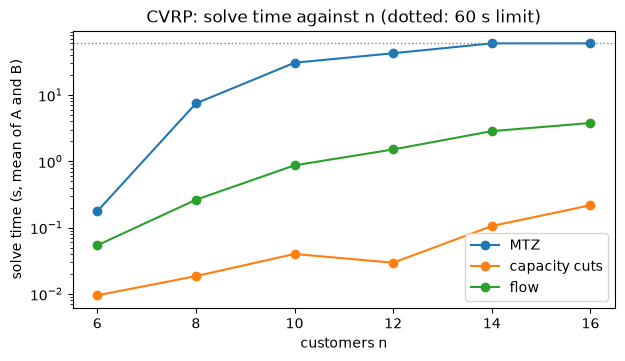

In [2]:
import matplotlib.pyplot as plt

RES = ROOT / "results"
cvrp = pd.read_csv(RES / "exact_cvrp.csv")
tw = pd.read_csv(RES / "exact_cvrptw.csv")
td = pd.read_csv(RES / "exact_traffic.csv")
for df in (cvrp, tw, td):
    df["root_gap"] = (100 * (df.objective - df.lp_bound) / df.objective).clip(lower=0)
    df["optimal"] = df.status.eq("Optimal")

t41 = cvrp.groupby("model").agg(
    proven_optimal=("optimal", "sum"),
    runs=("optimal", "size"),
    median_s=("seconds", "median"),
    mean_root_gap=("root_gap", "mean"),
)
display(t41.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for model, g in cvrp.groupby("model"):
    m = g.groupby("n").seconds.mean()
    ax.plot(m.index, m.values, marker="o", label=model)
ax.axhline(60, color="grey", ls=":", lw=1)
ax.set(yscale="log", xlabel="customers n", ylabel="solve time (s, mean of A and B)",
       title="CVRP: solve time against n (dotted: 60 s limit)")
ax.legend()
plt.show()

**Reading 4.1.** The capacity cut formulation proves every optimum (12 of 12) in at most 0.35 s,
because its LP relaxation is almost tight (mean root gap 0.6 %); the flow formulation also proves
all of them, in at most 4.4 s; MTZ, whose relaxation is far from the optimum (root gap 50 %), stops
at the 60 s limit from $n = 10$ on clustered B and $n = 14$ on random A. The strength of the LP
relaxation, not the number of variables, decides how far each CVRP formulation goes here.

In [3]:
t42 = tw.assign(
    bound_gap=(100 * (tw.objective - tw.bound) / tw.objective).clip(lower=0),
    tabu_gap=100 * (tw.tabu - tw.objective) / tw.objective,
)[["instance", "n", "status", "seconds", "objective", "bound", "bound_gap", "root_gap", "tabu",
   "tabu_gap"]]
display(t42.round(2))

,instance,n,status,seconds,objective,bound,bound_gap,root_gap,tabu,tabu_gap
0,C101[:5],5,Optimal,0.06,42.3,42.3,0.00,44.90,42.3,0.00
1,C101[:10],10,Optimal,0.02,58.1,58.1,0.00,18.15,58.1,-0.00
2,C101[:15],15,Optimal,0.03,141.6,141.6,0.00,29.57,141.6,-0.00
3,C101[:20],20,Optimal,0.05,175.0,175.0,0.00,16.00,175.0,-0.00
4,C101[:25],25,Optimal,0.08,191.3,191.3,0.00,13.86,191.3,0.00
5,C101[:50],50,Optimal,0.29,362.4,362.4,0.00,10.88,362.4,0.00
6,C101[:75],75,Optimal,1.05,649.2,649.2,0.00,17.83,649.2,0.00
7,C101[:100],100,Optimal,3.06,827.3,827.3,0.00,9.64,827.3,0.00
8,R101[:5],5,Optimal,0.02,156.2,156.2,0.00,16.53,156.2,0.00
9,R101[:10],10,Optimal,0.05,269.2,269.2,0.00,26.31,269.2,0.00


**Reading 4.2.** With time windows the ILP proves the optimum of the full C101 and R101 (100
customers) in about 3 s, and its values equal the best known ones (827.3 and 1637.7), which checks
both the model and the distance convention. On RC101 it stops at the 60 s limit from $n = 50$ on,
with a gap between solution and bound of 6 to 13 %. The root gap does not explain this (R101 has
50 % and is proven in 3 s): mixed clustered and random customers make the branching harder. One
Tabu Search run of 5 s matches the optimum on 18 of the 21 proven
cases (at most 1.1 % above it) and beats the ILP's best solution on RC101 with 50 customers: the
exact method is the reference on small or tight cases, a metaheuristic is needed beyond them.

,instance,n,status,seconds,objective,bound,bound_gap,lp_bound,variables
0,C101[:3],3,Optimal,0.39,350.64,350.64,0.00,-3708.0,342
1,C101[:4],4,Optimal,1.26,443.55,443.55,0.00,-4944.0,488
2,C101[:5],5,Optimal,2.62,542.06,542.06,0.00,-6180.0,660
3,C101[:6],6,Optimal,4.75,647.82,647.76,0.01,-7416.0,864
4,C101[:7],7,Optimal,30.70,740.19,740.15,0.01,-8652.0,1106
5,C101[:8],8,Optimal,52.85,835.41,835.35,0.01,-9888.0,1392
6,C101[:9],9,TimeLimit,60.20,960.11,-1263.35,NaN,-11124.0,1728
7,C101[:10],10,TimeLimit,60.26,1080.78,-1480.07,NaN,-12360.0,2120
8,R101[:3],3,Optimal,0.15,161.64,161.64,0.00,-690.0,342
9,R101[:4],4,Optimal,0.53,217.04,217.04,0.00,-920.0,488


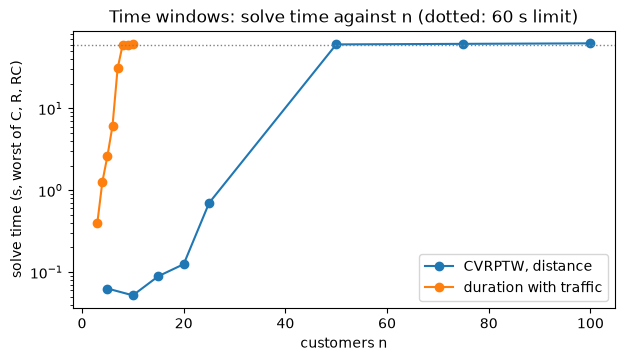

In [4]:
gap = (100 * (td.objective - td.bound) / td.objective).clip(lower=0)
td["bound_gap"] = gap.where(td.bound > 0)  # n/a when the bound is not positive
display(td[["instance", "n", "status", "seconds", "objective", "bound", "bound_gap", "lp_bound",
            "variables"]].round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for label, df in [("CVRPTW, distance", tw), ("duration with traffic", td)]:
    m = df.groupby("n").seconds.max()
    ax.plot(m.index, m.values, marker="o", label=label)
ax.axhline(60, color="grey", ls=":", lw=1)
ax.set(yscale="log", xlabel="customers n", ylabel="solve time (s, worst of C, R, RC)",
       title="Time windows: solve time against n (dotted: 60 s limit)")
ax.legend()
plt.show()

**Reading 4.3.** The model with traffic proves the optimum up to 7 customers on every instance
(8 on C101 and R101), then stops at the 60 s limit with a bound far below the solution. Its LP
relaxation is useless as a bound: with $x$ fractional, the big-M of (8) is switched off, every
truck "returns" at $e_0$ and leaves at $l_0$, and the LP value is $-n\,(l_0 - e_0)$. One departure
hour per stop multiplies the variables by 24 (48 here) and the big-M keeps the relaxation weak, so the exact model with traffic serves to check the
definition of the objective on small cases (section 3), not to plan a day.

**Where the exact approach stops.** Without windows: MTZ at 10 to 14 customers; flow and capacity
cuts solve every tested size (up to 16, at most 4.4 s), so their limit lies beyond. With windows, without traffic: 100 customers when the windows
are tight on clustered or random customers (C101, R101), fewer than 50 on mixed RC101. With
traffic: 7 to 8 customers. Beyond that, the metaheuristics of sections 5 to 8 give the solutions,
and the ILP values of 4.2 remain the reference used to measure their gap.

<a id="s5"></a>
## 5. Chosen metaheuristic: GRASP-ILS

Three metaheuristics from the course list were implemented on the same instance, solution and
evaluator code and compared under one protocol (section 8): **Tabu Search** (Pablo,
`src/cvrp/tabu.py`), **Simulated Annealing** (Dag, `src/cvrp/sa.py`, compiled with numba) and
**GRASP** with an iterated local search inside each iteration (Farida, `src/cvrp/grasp.py`). The
rule fixed before the campaign was: feasible on every run, then lowest mean gap, then lowest mean
time. GRASP-ILS is feasible on all 500 test runs and has the lowest mean gap (1.16 %, against
1.70 % for SA and 3.98 % for Tabu Search), with every pairwise difference significant: it is the
chosen method. Its full study is `notebooks/04_grasp.ipynb`.

| Component | GRASP-ILS |
| --- | --- |
| Encoding | a list of routes, each a list of customers; the depot is implicit at both ends |
| Initialization | randomized adaptive parallel insertion: each unrouted customer keeps its cheapest feasible insertion per route; score = regret $c_1 - (c_2 - c_1)$; a customer is drawn from the restricted candidate list $\{u : \text{score}(u) \le s_{\min} + \alpha (s_{\max} - s_{\min})\}$; a new route starts from a customer far from the depot or with an early due time; if more than $K$ routes are opened, the smallest ones are emptied and reinserted |
| Neighborhoods | relocate, swap, 2-opt*, Or-opt (chains of 2 or 3), cross-exchange (segments up to 2), 2-opt; only between a customer and its 20 nearest customers (granular) |
| Local search | variable neighborhood descent: after any improvement restart from the first neighborhood; first improvement |
| Time windows | each route stores the earliest start $A_k$ and the latest feasible start $Z_k$ of every position (Savelsbergh, 1992), so a move is checked in $O(1)$ plus the moved segment; intra-route 2-opt re-checks the route |
| Guidance | multi-start (diversification) by the randomized construction; intensification by 90 kicks per iteration: remove a cluster of 10 to 20 % of the customers, reinsert them at their cheapest place, descend, keep only if shorter |
| Acceptance | a solution replaces the best only if it is feasible for the shared evaluator and shorter |
| Stopping criterion | wall-clock time limit (20 s in the benchmark), checked between iterations and kicks |
| Parameters | $\alpha = 0.3$, first improvement, 90 kicks: the best of 12 settings on the 6 tuning instances (section 8.1) |
| Objective | a parameter: total distance (benchmark) or total route duration with hourly traffic, the objective of section 3 (`objective="duration"`) |

The two other algorithms, for the comparison of section 8:

| Component | Tabu Search | Simulated Annealing |
| --- | --- | --- |
| Encoding | list of routes | list of routes (arrays, compiled with numba) |
| Initialization | time-oriented nearest neighbor (Solomon, 1987) | randomized cheapest feasible insertion |
| Neighborhood | relocate, swap, 2-opt*, 2-opt between a customer and one of its 15 nearest | relocate a customer or a chain of 2 or 3, swap, 2-opt, 2-opt*, between random routes |
| Step | best non-tabu move among 200 sampled | one random feasible move |
| Guidance | a moved customer is tabu for a tenure drawn in $[t/2, 3t/2]$; aspiration if a tabu move gives a new best | Metropolis acceptance, $T(\tau) = T_0 (T_f / T_0)^{\tau}$, $\tau$ = elapsed fraction of the time limit, $T_0 = \max(1, f \cdot \text{start cost})$ |
| Stopping | time limit | time limit |
| Tuned | tenure $t = 20$, 200 candidates (grid of 9) | $f = 0.005$, $T_f = 0.005$ (grid of 12) |
| Fixed | 15 nearest neighbors | move probabilities (uniform) |

<a id="s6"></a>
## 6. Implementation

`grasp(inst, GRASPParams(...), seed)` reads the shared `Instance`, returns a `GRASPResult`
(best `Solution`, cost, runtime, iterations, per-iteration history) and re-checks the kept
solution with `Solution.violations`, independent of the internal caches. The demo runs the chosen
parameters for 5 s on one instance of each family (clustered, random, mixed), with the distances
of the benchmark.

GRASPParams(alpha=0.3, iterations=1000000000, improvement='first', enhanced=True, max_local_rounds=100000, n_neighbors=20, construction='regret', tw_weight=0.0, perturb_kicks=90, time_limit=5.0, objective='distance', start_min=480.0)


,instance,routes,cost,best known,gap %,iterations,seconds,feasible
0,C105,10,827.3,827.3,0.00,12,5.0,True
1,R205,4,968.8,949.8,2.00,9,5.0,True
2,RC105,16,1531.0,1513.7,1.14,7,5.0,True


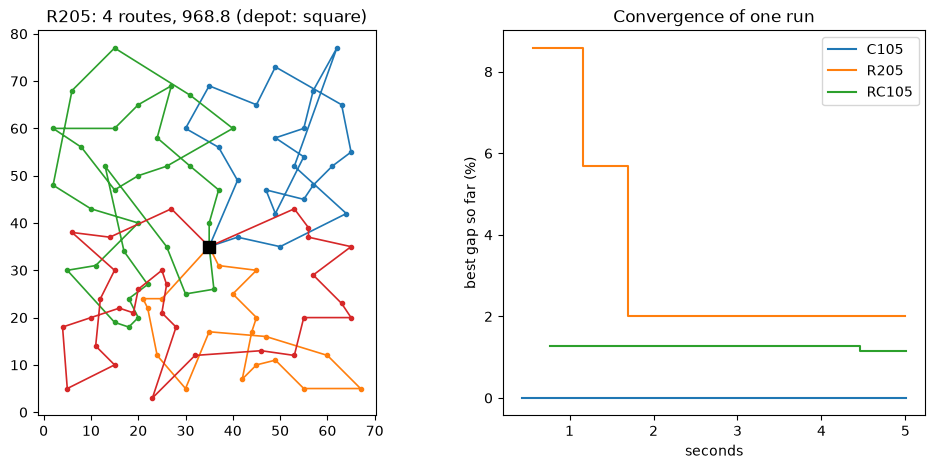

In [5]:
import solomon_study as study
from cvrp.grasp import GRASPParams, grasp

CHOSEN = {"alpha": 0.3, "improvement": "first", "perturb_kicks": 90}
params = GRASPParams(iterations=10**9, time_limit=5.0, **CHOSEN)
print(params)

demo, runs = [], {}
for name in ["C105", "R205", "RC105"]:
    inst = study.load(name)
    res = grasp(inst, params, seed=1)
    runs[name] = (inst, res)
    demo.append({"instance": name, "routes": len(res.best), "cost": round(res.cost, 1),
                 "best known": inst.best_known,
                 "gap %": round(100 * (res.cost - inst.best_known) / inst.best_known, 2),
                 "iterations": res.iterations, "seconds": round(res.runtime, 1),
                 "feasible": res.best.is_feasible(inst)})
display(pd.DataFrame(demo))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
inst, res = runs["R205"]
for k, route in enumerate(res.best.routes):
    path = [0, *route, 0]
    axes[0].plot(*inst.coords[path].T, "-o", ms=3, lw=1.2, color=plt.cm.tab10(k % 10))
axes[0].plot(*inst.coords[0], "ks", ms=9)
axes[0].set(title=f"R205: {len(res.best)} routes, {res.cost:.1f} (depot: square)", aspect="equal")
for name, (inst, res) in runs.items():
    h = pd.DataFrame(res.history)
    axes[1].step(h.seconds, 100 * (h.best - inst.best_known) / inst.best_known, where="post",
                 label=name)
axes[1].set(xlabel="seconds", ylabel="best gap so far (%)", title="Convergence of one run")
axes[1].legend()
plt.show()

In 5 s every run is feasible and within a few percent of the best known value; most of the gain
comes in the first iterations, and the later ones polish the solution through the kicks.

<a id="s7"></a>
## 7. Test cases

The automated tests (`pytest`, 76 tests) cover the shared evaluator, every solver and the
models: known optimum of a hand-made 4-customer instance (`tests/conftest.py`, cost
$10 + \sqrt{2}$), agreement between the fast time-window checks of GRASP and the shared evaluator,
reproducibility with a seed, a local search that never worsens, the traffic cost of GRASP equal to
the Tabu Search duration, and the exact optimum of the toy instance of notebook 01 (section 3).

The cell below checks GRASP-ILS against the **proven optima** of section 4.2: the first 10, 25 and
50 customers of C101, R101 and RC101, 2 s per run.

In [6]:
from exact_study import head, solomon

opt = pd.read_csv(RES / "exact_cvrptw.csv").set_index("instance")
quick = GRASPParams(iterations=10**9, time_limit=2.0, **CHOSEN)
rows = []
for name in ["C101", "R101", "RC101"]:
    for n in [10, 25, 50]:
        inst = head(solomon(name), n, fleet=n)
        res = grasp(inst, quick, seed=1)
        ref = opt.loc[inst.name]
        diff = round(100 * (res.cost - ref.objective) / ref.objective, 2) + 0.0
        rows.append({"instance": inst.name, "ILP": round(ref.objective, 1),
                     "ILP status": ref.status, "GRASP-ILS (2 s)": round(res.cost, 1),
                     "difference %": diff, "feasible": res.best.is_feasible(inst)})
display(pd.DataFrame(rows))

,instance,ILP,ILP status,GRASP-ILS (2 s),difference %,feasible
0,C101[:10],58.1,Optimal,58.1,0.00,True
1,C101[:25],191.3,Optimal,191.3,0.00,True
2,C101[:50],362.4,Optimal,362.4,0.00,True
3,R101[:10],269.2,Optimal,269.2,0.00,True
4,R101[:25],617.1,Optimal,617.1,0.00,True
5,R101[:50],1044.0,Optimal,1044.0,0.00,True
6,RC101[:10],185.5,Optimal,185.5,0.00,True
7,RC101[:25],461.1,Optimal,461.1,0.00,True
8,RC101[:50],970.9,TimeLimit,957.1,-1.42,True


GRASP-ILS finds the proven optimum on all eight sub-instances where the ILP proves one, and on
RC101 with 50 customers it is 1.4 % shorter than the best solution the ILP finds in 60 s.

<a id="s8"></a>
## 8. Experimental study

**Questions.** Which metaheuristic gives the lowest gap to the best known solution at equal time?
Is the difference significant, and does it hold on every family of instances?

| Item | Value |
| --- | --- |
| Instances | the 56 Solomon CVRPTW instances, 100 customers (C1, C2, R1, R2, RC1, RC2) |
| Distances | Euclidean, truncated to one decimal, the convention of the best known values (checked on all 56) |
| Objective | total distance, travel time = distance, no traffic (section 3) |
| Tuning set | C101, C201, R101, R201, RC101, RC201, seeds 101 and 102 |
| Test set | the other 50 instances, seeds 1 to 10: 500 runs per algorithm |
| Budget | 20 s of wall-clock time per run, construction included, the same for every algorithm |
| Machine | one Apple M2 (8 cores), 7 runs in parallel, Python 3.13; the jobs of the three algorithms are interleaved |
| Metric | gap $= 100\,(\text{cost} - \text{BKS}) / \text{BKS}$; GRASP-ILS and SA solutions checked by the shared evaluator, Tabu Search ones by its cost function (capacity, windows, return to the depot), and every solution for coverage and cost |
| Target | the brief caps the grade when the gap exceeds 7 to 10 %; 7 % is the stricter reading |
| Tests | Friedman on the per-instance mean gaps, then Wilcoxon signed rank per pair with Holm correction, 5 % |

`python experiments/solomon_study.py tune`, then `run`, writes the two CSV files read below.

<a id="s81"></a>
### 8.1 Tuning

In [7]:
tuning = pd.read_csv(RES / "solomon_tuning.csv")
bench = pd.read_csv(RES / "solomon_benchmark.csv")
NAMES = {"grasp": "GRASP-ILS", "sa": "SA", "tabu": "Tabu Search"}
COLORS = {"grasp": "#2a78d6", "sa": "#eb6834", "tabu": "#1baf7a"}
pd.set_option("display.max_colwidth", None)

t = tuning.groupby(["algorithm", "params"]).gap.mean().reset_index()
chosen = t.loc[t.groupby("algorithm").gap.idxmin()].set_index("algorithm")
chosen["settings tried"] = t.groupby("algorithm").size()
chosen["worst setting gap"] = t.groupby("algorithm").gap.max()
display(chosen.rename(index=NAMES, columns={"gap": "tuning gap %"}).round(2))

,params,tuning gap %,settings tried,worst setting gap
algorithm,,,,
GRASP-ILS,"{'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}",1.17,12,3.13
SA,"{'initial_temperature_factor': 0.005, 'final_temperature': 0.005}",0.56,12,0.78
Tabu Search,"{'tenure': 20, 'candidates': 200}",2.11,9,9.96


Each algorithm keeps the setting with the lowest mean gap on the tuning set only. The spread
between the best and the worst setting is large for Tabu Search (the candidate list size matters)
and for GRASP (the kicks matter), and small for SA, whose 12 temperature settings stay within
0.3 points. SA is best on the tuning set (0.56 % against 1.17 %); the test set, nine times larger,
decides.

<a id="s82"></a>
### 8.2 Results on the 50 test instances

In [8]:
assert bench.feasible.all() and len(bench) == 1500
bench["class"] = bench.instance.str.extract(r"^([A-Z]+\d)")[0]
overall = bench.groupby("algorithm").agg(
    mean_gap=("gap", "mean"),
    std_gap=("gap", "std"),
    median_gap=("gap", "median"),
    worst_gap=("gap", "max"),
    runs_at_bks=("gap", lambda g: int((g <= 1e-6).sum())),
    runs_within_7=("gap", lambda g: 100 * (g <= 7).mean()),
    routes=("routes", "mean"),
    seconds=("seconds", "mean"),
).sort_values("mean_gap")
display(overall.rename(index=NAMES).round(2))

by_class = bench.pivot_table(index="class", columns="algorithm", values="gap", aggfunc="mean")
display(by_class[["grasp", "sa", "tabu"]].rename(columns=NAMES).round(2))

,mean_gap,std_gap,median_gap,worst_gap,runs_at_bks,runs_within_7,routes,seconds
algorithm,,,,,,,,
GRASP-ILS,1.16,1.41,0.68,9.82,162,99.2,8.00,20.01
SA,1.70,1.43,1.58,6.51,106,100.0,8.91,20.01
Tabu Search,3.98,3.15,3.96,14.03,110,83.2,9.09,20.00


algorithm,GRASP-ILS,SA,Tabu Search
class,,,
C1,0.02,0.44,0.78
C2,0.01,0.73,1.26
R1,0.68,1.59,3.54
R2,2.22,2.37,5.78
RC1,1.30,2.39,5.62
RC2,2.73,2.65,6.82


GRASP-ILS has the lowest mean (1.16 %) and median gap and reaches the best known value on 162 of
its 500 runs; SA has the smallest worst case (6.5 %, every run within 7 %); Tabu Search is about
3.4 times the mean gap of GRASP-ILS. By class, GRASP-ILS is best on five of six; on RC2,
mixed customers with long routes, SA is slightly ahead (2.65 % against 2.73 %). Type 2 classes
(few long routes) are the hardest for all three.

In [9]:
per_inst = bench.groupby(["instance", "algorithm"]).gap.agg(["mean", "std", "min"]).unstack()
per_inst.columns = [f"{NAMES[a]} {s}" for s, a in per_inst.columns]
seed_std = bench.groupby(["instance", "algorithm"]).gap.std().unstack().mean()
print("mean over instances of the seed std (gap points):",
      ", ".join(f"{NAMES[a]} {v:.2f}" for a, v in seed_std.items()))
order = [f"{NAMES[a]} {s}" for a in ["grasp", "sa", "tabu"] for s in ["mean", "std", "min"]]
display(per_inst[order].round(2))

mean over instances of the seed std (gap points): GRASP-ILS 0.47, SA 0.78, Tabu Search 1.45


,GRASP-ILS mean,GRASP-ILS std,GRASP-ILS min,SA mean,SA std,SA min,Tabu Search mean,Tabu Search std,Tabu Search min
instance,,,,,,,,,
C102,0.00,0.00,0.00,0.49,0.42,0.00,0.81,1.44,0.00
C103,0.00,0.00,0.00,1.80,1.44,0.00,3.28,2.50,1.10
C104,0.17,0.24,0.00,0.57,1.04,0.00,2.16,1.62,0.46
C105,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00
C106,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
C107,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
C108,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
C109,0.00,0.00,0.00,0.63,1.33,0.00,0.00,0.00,0.00
C202,0.00,0.00,0.00,1.23,2.00,-0.00,0.00,0.00,-0.00


Per instance (mean, seed standard deviation and best over 10 seeds): GRASP-ILS is also the most
stable from one seed to the next (0.47 points against 0.78 for SA and 1.45 for Tabu Search), and
its best run reaches the best known value on all 15 C instances and on 5 of the 11 R1 ones.

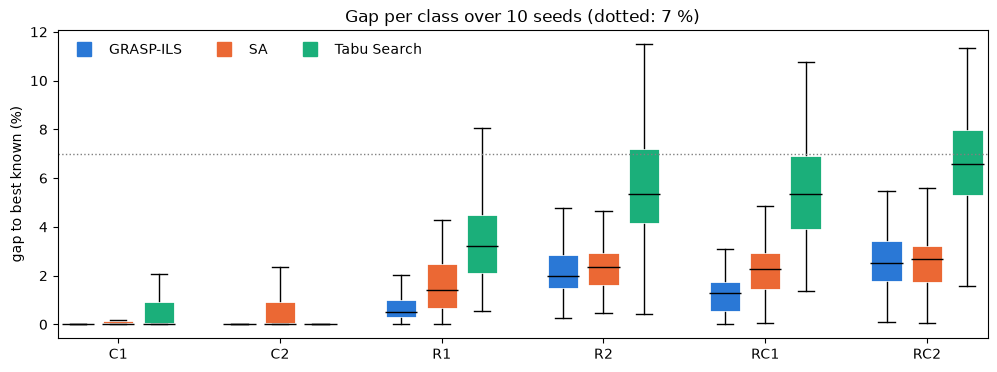

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
classes = sorted(bench["class"].unique())
for k, algo in enumerate(["grasp", "sa", "tabu"]):
    data = [bench[(bench["class"] == c) & (bench.algorithm == algo)].gap for c in classes]
    bp = ax.boxplot(data, positions=[i * 4 + k for i in range(len(classes))], widths=0.8,
                    patch_artist=True, showfliers=False)
    for box in bp["boxes"]:
        box.set(facecolor=COLORS[algo], edgecolor="white", linewidth=2)
    for med in bp["medians"]:
        med.set(color="black")
    ax.plot([], [], "s", color=COLORS[algo], ms=10, label=NAMES[algo])
ax.set_xticks([i * 4 + 1 for i in range(len(classes))], classes)
ax.axhline(7, color="grey", ls=":", lw=1)
ax.set(ylabel="gap to best known (%)", title="Gap per class over 10 seeds (dotted: 7 %)")
ax.legend(ncol=3, frameon=False)
plt.show()

The boxes show the spread over instances and seeds: GRASP-ILS is nearly always at the best known
value on the clustered classes, and its spread grows on the random and mixed type 2 classes, where
SA is as good. Outliers are hidden; the worst runs are in the table above.

<a id="s83"></a>
### 8.3 Statistical tests

In [11]:
from scipy.stats import friedmanchisquare, wilcoxon

means = bench.groupby(["instance", "algorithm"]).gap.mean().unstack()
stat, p = friedmanchisquare(means.grasp, means.sa, means.tabu)
print(f"Friedman on 50 instances: chi2 = {stat:.1f}, p = {p:.1e}")
pairs = []
for a, b in itertools.combinations(["grasp", "sa", "tabu"], 2):
    w, pv = wilcoxon(means[a], means[b])
    pairs.append({"pair (A vs B)": f"{NAMES[a]} vs {NAMES[b]}", "W": w, "p": pv,
                  "A better on": int((means[a] < means[b] - 1e-9).sum()),
                  "B better on": int((means[b] < means[a] - 1e-9).sum()),
                  "ties": int((abs(means[a] - means[b]) <= 1e-9).sum()),
                  "n used": int((abs(means[a] - means[b]) > 1e-9).sum())})
pairs = pd.DataFrame(pairs).sort_values("p").reset_index(drop=True)
m = len(pairs)
pairs["Holm p"] = (pairs.p * (m - pairs.index)).cummax().clip(upper=1)
pairs["significant at 5 %"] = pairs["Holm p"] < 0.05
display(pairs.style.format({"W": "{:.0f}", "p": "{:.1e}", "Holm p": "{:.1e}"}))

Friedman on 50 instances: chi2 = 57.1, p = 4.0e-13


,pair (A vs B),W,p,A better on,B better on,ties,n used,Holm p,significant at 5 %
0,GRASP-ILS vs Tabu Search,0,2.4e-08,41,0,9,41,7.3e-08,True
1,SA vs Tabu Search,19,2.8e-08,40,4,6,44,7.3e-08,True
2,GRASP-ILS vs SA,194,7.5e-04,31,12,7,43,7.5e-04,True


The three algorithms differ (Friedman), and every pair differs after the Holm correction (the
Wilcoxon test drops tied instances, hence "n used"):
GRASP-ILS beats SA on 31 instances, SA beats it on 12, and 7 are ties (instances solved to the best
known value by both); GRASP-ILS is never worse than Tabu Search (better on 41, 9 ties) and SA is
better than it on 40 instances, worse on 4.

**Behavior.** The three spend the 20 s very differently: SA makes about 42 million compiled move
attempts, Tabu Search about 18 000 iterations of 200 sampled moves, GRASP-ILS about 19 iterations
of construction, descent and 90 kicks. Few deep searches from good starts beat many cheap moves
here. Tabu Search makes a similar number of iterations on every class (about 16 100 to 20 100), so
its larger gap on type 2 is not a matter of speed. SA is compiled and the others are not, so "equal time" mixes the
algorithm with its implementation: this favors SA, which still comes second.

**Conclusion.** GRASP-ILS is chosen: feasible on every run, mean gap 1.16 %, significantly better
than SA and Tabu Search, and within the 7 % target on 99.2 % of its runs (worst run 9.8 %, RC2).

<a id="s9"></a>
## 9. Scale, real road networks and the night

**Questions** (review of 10 November). Where does each algorithm break when $n$ grows to 10 000?
Does the ranking of section 8 hold on real road networks, in two countries? What changes when the
fleet leaves at night? How sensitive is each algorithm to its own parameters?

| Study | Data | Budget, seeds | Quality measure | Script |
| --- | --- | --- | --- | --- |
| 9.1 | Homberger R1 with 400, 800, 1 000 customers, time windows | 20, 60, 120 s; 3 seeds | gap to best known | `experiments/scale_study.py homberger` |
| 9.2 | uniform synthetic CVRP, 10 000 customers, $Q = 100$, demand 1 to 10 | 300 s; 1 seed, one run at a time | gap to the best run and to a lower bound | `experiments/scale_study.py synthetic` |
| 9.3 | Paris and São Paulo, 999 real customers, road network distances (RRNCO, OpenStreetMap) | 60 s; 5 seeds; control at 300 s | gap to the best run | `experiments/city_study.py run`, `control` |
| 9.4 | the same cities, duration with hourly traffic, departure 08:00 or 22:00 | 60 s; 5 seeds | minutes | `experiments/city_study.py run` |
| 9.5 | the 6 tuning instances, one parameter at a time around the tuned value | 20 s; 3 seeds | gap to best known | `experiments/sensitivity.py` |

Every algorithm keeps its tuned setting (section 8.1; SA uses the final setting of
`notebooks/SA.ipynb`, initial factor 0.01, in 9.1 and 9.2), every solution is checked by the shared
evaluator, and all runs are made on the M2 of section 8: SA numbers differ from those of
`notebooks/SA.ipynb`, made on another machine, so only this table compares algorithms.

<a id="s91"></a>
### 9.1 From 100 to 1 000 customers

algorithm          GRASP-ILS            SA   Tabu Search
n    time_limit                                         
400  20.0        3.67 ± 0.07    5.16 ± 0.7  15.37 ± 1.07
     60.0        3.19 ± 0.32   4.91 ± 0.94  13.85 ± 0.83
     120.0       2.75 ± 0.29   3.53 ± 0.28   12.3 ± 0.98
800  20.0         8.4 ± 0.48  14.36 ± 0.88  32.32 ± 0.28
     60.0        7.16 ± 0.01  10.98 ± 0.89   29.9 ± 0.48
     120.0        6.71 ± 0.4   8.68 ± 0.58  28.33 ± 0.62
1000 20.0        9.91 ± 0.77  21.75 ± 1.19  37.33 ± 1.94
     60.0        9.01 ± 0.76  15.03 ± 0.69  33.83 ± 2.65
     120.0       7.81 ± 0.44  10.45 ± 1.57  31.74 ± 1.94

iterations                       routes              
algorithm      grasp           sa     tabu  grasp     sa   tabu
n                                                              
400              5.0  113312711.0  56115.0   44.0   47.0   59.0
800              1.0   56292011.0  44838.0   87.0   93.0  140.0
1000             1.0   50571577.0  44579.0  106.0  115.0  171.0

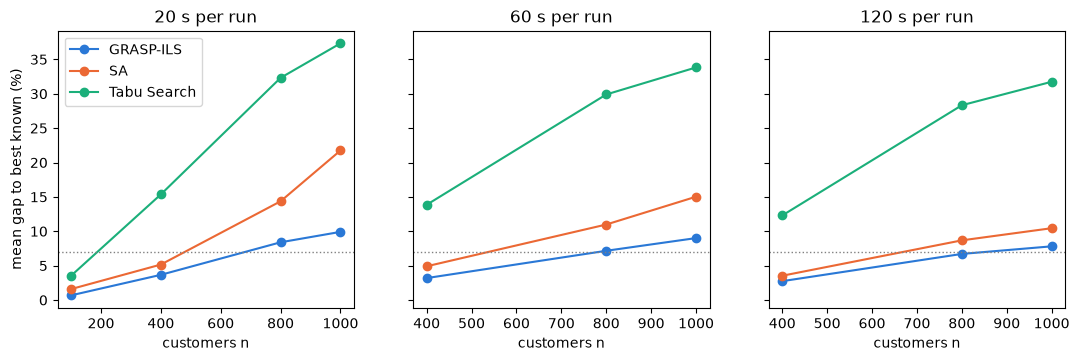

In [12]:
NAMES = {"grasp": "GRASP-ILS", "sa": "SA", "tabu": "Tabu Search"}
scale = pd.read_csv(RES / "scale_homberger.csv")
assert scale.feasible.all() and len(scale) == 81
r1 = bench[bench["class"] == "R1"].groupby("algorithm").gap.mean()  # 100 customers, 20 s
gap = scale.pivot_table(index=["n", "time_limit"], columns="algorithm", values="gap", aggfunc="mean")
spread = scale.pivot_table(index=["n", "time_limit"], columns="algorithm", values="gap", aggfunc="std")
display((gap.round(2).astype(str) + " ± " + spread.round(2).astype(str))[list(NAMES)].rename(columns=NAMES))
display(scale.pivot_table(index="n", columns="algorithm", values=["routes", "iterations"],
                          aggfunc="mean").round(0))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, t in zip(axes, [20.0, 60.0, 120.0]):
    for algo in NAMES:
        g = gap.xs(t, level="time_limit")[algo]
        xs, ys = ([100] if t == 20 else []) + list(g.index), ([r1[algo]] if t == 20 else []) + list(g)
        ax.plot(xs, ys, marker="o", color=COLORS[algo], label=NAMES[algo])
    ax.axhline(7, color="grey", ls=":", lw=1)
    ax.set(title=f"{t:.0f} s per run", xlabel="customers n")
axes[0].set_ylabel("mean gap to best known (%)")
axes[0].legend()
plt.show()

**Reading 9.1.** GRASP-ILS has the lowest gap at every size and every budget, and it degrades
slowest: 0.68 % on the 100 customer R1 class, 9.9 % at 1 000 customers with 20 s. Each algorithm
breaks for its own reason, visible in the internal measures:

- **Tabu Search: the number of trucks.** At 1 000 customers it uses 171 routes against 106 for
  GRASP-ILS (60 % more). Its start is a nearest neighbor that opens a route whenever a window
  blocks, and relocate and swap rarely empty a whole route, so six times more time only moves its
  gap from 37.3 % to 31.7 %: the extra trucks stay.
- **SA: the time.** It makes 16 million moves in 20 s at 1 000 customers, 16 000 per customer
  against 420 000 on Solomon, and its geometric cooling ends before the plan is good. Its gap is
  halved from 20 to 120 s (21.8 % to 10.5 %), the largest gain of the three.
- **GRASP-ILS: the time per iteration.** From 800 customers on it completes one or two iterations
  in 120 s, so the multi-start and most kicks never happen; what carries it is one regret
  construction and one descent. It reaches the 7 % target up to 800 customers with 120 s
  (6.7 %), not at 1 000 (7.8 %).

The seed spread stays below 2 points everywhere, so these differences are not noise.

<a id="s92"></a>
### 9.2 10 000 customers

In [13]:
import scale_study

syn = pd.read_csv(RES / "scale_synthetic.csv")

big = scale_study.synthetic()
radial = 2 * (big.dist[0, 1:] * big.demands[1:]).sum() / big.capacity  # each route >= 2 max d_0i
best = syn.loc[syn.feasible, "cost"].min()
syn["gap to best run %"] = 100 * (syn.cost / best - 1)
syn["gap to bound %"] = 100 * (syn.cost / radial - 1)
print(f"lower bound 2 sum(d_0i q_i) / Q = {radial:.0f}; minimum trucks = "
      f"{int(np.ceil(big.demands.sum() / big.capacity))}")
display(syn[["algorithm", "feasible", "cost", "routes", "iterations", "seconds",
             "gap to best run %", "gap to bound %", "error"]].round(2))

# the same construction from 1 000 to 5 000 customers, 60 s: where each method stops
sweep = pd.concat([pd.read_csv(RES / "scale_sweep.csv"), syn], ignore_index=True)
bounds = {}
for n in sorted(sweep.n.unique()):
    u = scale_study.synthetic(int(n))
    bounds[n] = 2 * (u.dist[0, 1:] * u.demands[1:]).sum() / u.capacity
sweep["above bound %"] = 100 * (sweep.cost / sweep.n.map(bounds) - 1)
sweep["ms per iteration"] = 1000 * sweep.seconds / sweep.iterations.where(sweep.iterations > 0)
display(sweep.pivot_table(index="n", columns="algorithm",
                          values=["above bound %", "seconds", "ms per iteration"]).round(2))

lower bound 2 sum(d_0i q_i) / Q = 423525; minimum trucks = 553


,algorithm,feasible,cost,routes,iterations,seconds,gap to best run %,gap to bound %,error
0,tabu,True,502256.85,553,146116,300.12,0.00,18.59,NaN
1,sa,True,779401.05,774,14277632,301.89,55.18,84.03,NaN
2,grasp,False,NaN,0,0,660.00,NaN,NaN,stopped after 660 s (observed 684 s without a solution)


above bound %                ms per iteration             seconds  \
algorithm         grasp      sa   tabu            grasp    sa  tabu   grasp   
n                                                                             
1000              45.62   64.63  46.05          60330.0  0.00  0.68   60.33   
2000              37.78   79.44  35.99          63320.0  0.00  0.76   63.32   
5000              39.76  102.37  25.92         125260.0  0.01  1.17  125.26   
10000               NaN   84.03  18.59              NaN  0.02  2.05  660.00   

                           
algorithm      sa    tabu  
n                          
1000        60.76   60.10  
2000        60.65   60.17  
5000        60.73   60.04  
10000      301.89  300.12

**Reading 9.2.** At 10 000 customers only Tabu Search gives a good plan. Without a best known value
we use the radial bound $2 \sum_i d_{0i} q_i / Q$: a route $r$ costs at least $2 \max_{i \in r} d_{0i}$
(out to its farthest customer and back), and since its load $\sum_{i \in r} q_i \le Q$, that is at
least $2 \sum_{i \in r} d_{0i} q_i / Q$; summing over the routes gives 423 525 here. Tabu Search ends 18.6 % above it with the minimum
of 553 trucks, after 146 000 iterations: its block neighbor lists keep one iteration cheap. SA ends
84 % above the bound with 774 trucks: 14 million moves are 1 400 per customer, against 420 000 per
customer on Solomon in 20 s, so its cooling ends long before the plan is good. GRASP-ILS never
returns: its clock is read only between iterations, and after 684 s (more than twice the budget)
its first iteration, a regret construction and a full descent, had not finished; we stopped it. **This is the limit of each method:** Tabu Search
scales through its neighbor lists, SA needs time in proportion to $n$, and GRASP-ILS's construction,
its strength up to 1 000 customers, is its wall at 10 000. One run each, made one at a time (the
800 MB matrix and a laptop with 8 GB under memory pressure), so these are orders of magnitude, not
statistics.

**Where each method stops** (same uniform construction, no windows, 60 s from 1 000 to 5 000
customers). At 1 000 customers GRASP-ILS and Tabu Search are equal (46 % above the bound); from
2 000 on Tabu Search pulls ahead (36 %, 26 %, 19 % at 2 000, 5 000, 10 000), its time per iteration
growing only from 0.7 to 2.1 ms. GRASP-ILS completes a single iteration everywhere, and that
iteration takes 60 s at 2 000, 125 s at 5 000 (twice the budget) and more than 684 s at 10 000: it
grows faster than $n^2$, so GRASP-ILS stops returning a plan within its budget between 2 000 and
5 000 customers, and stops returning one at all between 5 000 and 10 000. SA's move rate falls
with $n$ (1.0 million per second at 1 000, 0.16 at 5 000) and its gap to the bound rises to 102 %
at 5 000. The overrun of GRASP-ILS is a defect of our implementation (the clock is read only
between iterations), not of GRASP (section 10).

<a id="s93"></a>
### 9.3 Real road networks: Paris and São Paulo

In [14]:
metrics = pd.read_csv(RES / "city_metrics.csv").set_index("city")
display(metrics[["area_km2", "mean_trip_km", "mean_speed_kmh", "circuity", "asymmetry_pct"]].round(2))
city = pd.read_csv(RES / "city_benchmark.csv")
assert (city.feasible & city.cost_matches).all()
dist = city[city.objective == "distance"]
tab = dist.groupby(["city", "algorithm"]).agg(mean=("cost", "mean"), std=("cost", "std"),
                                            best=("cost", "min"), iterations=("iterations", "mean"))
control = pd.read_csv(RES / "city_control.csv")
best_all = pd.concat([dist, control]).groupby("city").cost.min()  # 60 s and 300 s runs
tab["gap to best of all runs %"] = 100 * (tab["mean"] / best_all.reindex(
    tab.index.get_level_values("city")).to_numpy() - 1)
display(tab.round(2))
display(control.groupby(["city", "algorithm", "time_limit", "kicks"], dropna=False)
        .agg(mean=("cost", "mean"), iterations=("iterations", "mean")).round(2))

,area_km2,mean_trip_km,mean_speed_kmh,circuity,asymmetry_pct
city,,,,,
Paris,8.88,2.49,20.53,1.51,24.04
Sao_Paulo,8.67,2.62,31.57,1.65,24.31


mean    std    best  iterations  \
city      algorithm                                      
Paris     grasp      360.94   8.49  352.53         1.0   
          sa         420.65  12.88  410.94  27887308.8   
          tabu       334.94   3.49  331.30     27795.8   
Sao_Paulo grasp      416.41   7.75  406.69         1.0   
          sa         459.80  10.20  442.70  31051059.2   
          tabu       382.90   5.01  376.87     36136.0   

                     gap to best of all runs %  
city      algorithm                             
Paris     grasp                          14.66  
          sa                             33.63  
          tabu                            6.40  
Sao_Paulo grasp                          16.74  
          sa                             28.90  
          tabu                            7.34

mean  iterations
city      algorithm time_limit kicks                    
Paris     grasp     60.0       0.0    357.51        1.00
                               10.0   357.51        1.00
                               30.0   357.51        1.00
                    300.0      90.0   344.66        1.00
          tabu      300.0      NaN    317.60   181589.67
Sao_Paulo grasp     60.0       0.0    412.23        1.00
                               10.0   412.23        1.00
                               30.0   412.23        1.00
                    300.0      90.0   412.23        1.00
          tabu      300.0      NaN    365.72   180915.00

**Reading 9.3.** The order of section 8 is reversed: on real roads without windows, **Tabu Search
wins** in both cities. Against the best plan of all runs (a Tabu Search run of 300 s: 314.8 km in
Paris, 356.7 km in São Paulo) its 60 s mean is 6.4 % and 7.3 % above, GRASP-ILS 14.7 % and 16.7 %,
SA 33.6 % and 28.9 %. Two facts explain it. Without windows, any truck can take any
customer, so the construction, the strength of GRASP-ILS, matters less, and what counts is the
number of improving moves per second: Tabu Search makes about 28 000 to 36 000 iterations in 60 s,
GRASP-ILS one. The control runs show that GRASP-ILS is limited by the size, not the budget: with 0,
10 or 30 kicks the cost is the same, because the first descent fills the minute, and with 300 s it
improves in Paris (357.5 to 344.7 km) but not in São Paulo, while Tabu Search improves in both.
Every plan uses the minimum of 57 trucks, so the differences are pure routing.

**France against Brazil.** The two networks cover the same area with the same number of customers.
São Paulo trips are longer (2.62 km against 2.49) and more circuitous (1.65 against 1.51): every
algorithm's distance is higher there, and the ranking is the same. What we cannot claim: the data
are travel matrices, not the road graphs, so density, mean degree and one way share are not
measured, and both cities use the same assumed traffic profile; the comparison is of network
geometry, not of traffic. Both matrices are asymmetric on 97 to 99 % of the pairs (one way streets), which a Euclidean
benchmark never tests.
We planned Lyon and Cairo; the RRNCO data gave validated road matrices for Paris and São Paulo, so
Brazil replaces Egypt under the same protocol.

<a id="s94"></a>
### 9.4 The night

In [15]:
dur = city[city.objective != "distance"].pivot_table(index=["city", "algorithm"], columns="objective",
                                                    values="cost", aggfunc="mean")
dur["night saving %"] = 100 * (1 - dur["duration 22:00"] / dur["duration 08:00"])
display(dur.round(1))

objective            duration 08:00  duration 22:00  night saving %
city      algorithm                                                
Paris     grasp              2390.0          1175.7            50.8
          tabu               1831.3          1014.0            44.6
Sao_Paulo grasp              1727.5           967.8            44.0
          tabu               1511.4           850.5            43.7

**Reading 9.4.** Leaving at 22:00 instead of 08:00 cuts the total duration by 44 % in both
cities (Tabu Search: 1 831 to 1 014 min in Paris, 1 511 to 850 in São Paulo). This is almost
entirely the traffic factor itself: $1 - 1/\rho_8 = 1 - 1/1.80 = 44.4$ %. Without service times
or windows the routes are short (32 min on average at 08:00, 18 min at night), so in the morning
plan only 1 of the 57 routes changes hour and none crosses midnight: every trip is priced at one
$\rho$, and the duration objective is the free flow one times a constant. **What the night shows is
therefore the size of the traffic effect, not a change of strategy by the algorithms.** A real
time dependent test needs routes that span several hours (service times and windows over a working
day), where leaving before the peak or crossing it changes which order is best; our model and both
solvers handle it (the duration cost reads $\rho$ at each departure), but this experiment does not
exercise it. The ranking does not change with the hour (Tabu Search ahead of GRASP-ILS by 14 to
31 %).

<a id="s95"></a>
### 9.5 Sensitivity to the intrinsic parameters

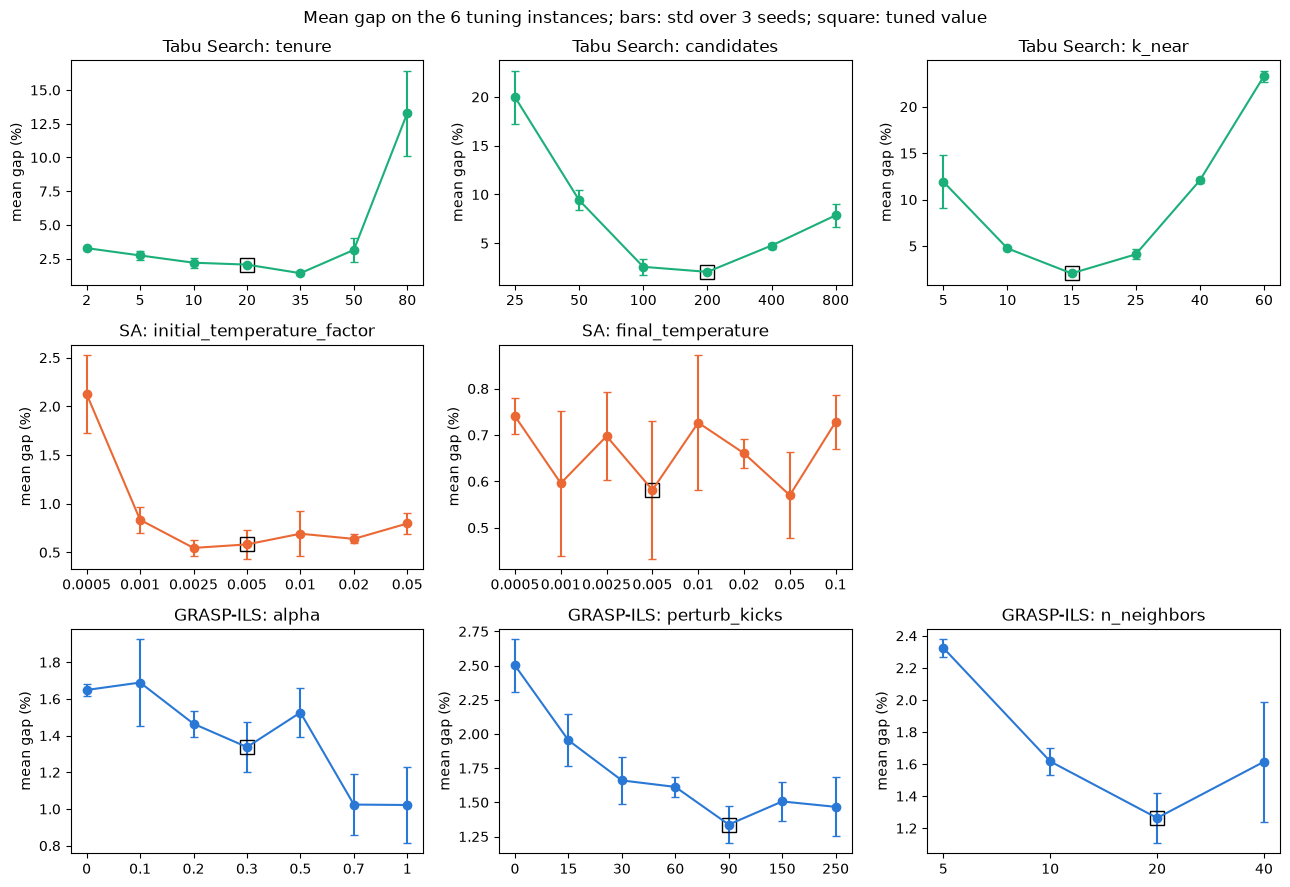

In [16]:
import sensitivity

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for row, algo in zip(axes, ["tabu", "sa", "grasp"]):
    cur = sensitivity.curves(algo)
    cur.loc[(cur.parameter == "n_neighbors") & (cur.value == 20), "tuned"] = True  # GRASP default
    groups = list(cur.groupby("parameter", sort=False))
    for ax in row[len(groups):]:
        ax.axis("off")
    for ax, (param, c) in zip(row, groups):
        x = range(len(c))
        ax.errorbar(x, c.mean_gap, yerr=c.seed_std, marker="o", color=COLORS[algo], capsize=3)
        ax.plot([i for i, t in zip(x, c.tuned) if t], c.mean_gap[c.tuned], "s", ms=10,
                mfc="none", mec="black")
        ax.set_xticks(list(x), [f"{v:g}" if isinstance(v, float) else str(v) for v in c.value])
        ax.set(title=f"{NAMES[algo]}: {param}", ylabel="mean gap (%)")
fig.suptitle("Mean gap on the 6 tuning instances; bars: std over 3 seeds; square: tuned value")
plt.tight_layout()
plt.show()

**Reading 9.5.** Each algorithm has its own fragile parameter, and it is the one that controls how
much search one iteration does.

- **Tabu Search is the most sensitive.** The candidate list must be balanced: 25 sampled moves make
  the step nearly random (20.0 %), 800 make each iteration 14 times slower than 25 (7.9 %); 200 is
  the bottom of a U. A tenure of 80 forbids so many moves that the search stalls (13.3 %), while 35
  is better than the tuned 20 (1.43 % against 2.06 %), a gain the 2-seed tuning missed. The neighbor
  list has a sharp optimum at 15 (5 neighbors: 11.9 %, 60: 23.3 %).
- **GRASP-ILS needs its kicks and its neighbor lists.** Without kicks (plain GRASP) the gap doubles
  (2.50 % against 1.34 %); 20 neighbors are best (5: 2.32 %). The tuned greediness $\alpha = 0.3$ is
  not the best: a more random construction ($\alpha$ 0.7 to 1.0, 1.02 %) does better at 100 customers,
  because the kicks repair a random start and diversity helps; at 1 000 customers, where only one
  iteration fits, the construction decides and this would need checking.
- **SA is the most robust.** Between an initial factor of 0.001 and 0.05 and a final temperature of
  0.0005 to 0.1 its gap stays between 0.54 and 0.83 %, a range comparable to the seed spread. It breaks only when
  the initial temperature tends to 0 (0.0005: 2.13 %): it then accepts almost no worse move and
  becomes a descent.

All curves are on the 6 tuning instances (100 customers), 3 seeds: they rank parameters, they do not
predict the gap at 1 000 customers. We kept the settings of section 8.1 because the test campaign
was fixed with them before this study; tenure 35 and $\alpha = 0.7$ are better here by 0.6 and 0.3
points, which would not change the ranking of section 8 (GRASP-ILS gains, Tabu Search stays
third), but retuning means rerunning the 1 500 test runs (section 10).

<a id="s96"></a>
### 9.6 Recommendation per scenario

| Scenario | Choice | Why, from our numbers |
| --- | --- | --- |
| about 100 customers, time windows | **GRASP-ILS** | 1.16 % mean gap on 500 runs, significantly ahead (8.2, 8.3) |
| 100 customers, a bad run is not acceptable | **SA** | worst run 6.5 %, every run within 7 %; ahead on RC2; robust to its parameters (8.2, 9.5) |
| 400 to 1 000 customers, time windows | **GRASP-ILS** | lowest gap at every size and budget; 6.7 % at 800 with 120 s (9.1) |
| 1 000 customers, time windows, long budget | **GRASP-ILS**, SA second | SA gains most from time (21.8 to 10.5 %) but stays behind (9.1) |
| about 1 000 customers, real road network, no windows | **Tabu Search** | 6 to 7 % from the best run of all against 15 to 17 % for GRASP-ILS, in both countries (9.3) |
| 10 000 customers, no windows | **Tabu Search** | 18.6 % above a lower bound with the minimum trucks; SA 84 %; GRASP-ILS no plan (9.2) |
| departure in the peak or at night | **Tabu Search** (as without traffic) | the ranking does not change with the hour; leaving at 22:00 saves 44 %, the traffic factor (9.4) |

**Our reading.** One confound first: our instances with windows go up to 1 000 customers, those
without windows from 1 000 to 10 000, so size and windows are not separated beyond 1 000; we did
not test 10 000 customers with windows. Within that limit: time windows make the construction decisive, so GRASP-ILS wins wherever windows
are tight and $n$ is at most 1 000. Without windows the number of improving moves per second
decides, so Tabu Search, whose iteration barely slows with $n$ thanks to its neighbor lists (about
20 500 iterations per 20 s at 400 customers, 9 700 at 10 000),
wins on large real networks. SA is the safe choice when the worst case matters and the budget is
generous. For the ADEME pilot, with windows and a few hundred deliveries per depot, we choose
GRASP-ILS; a city wide plan without windows would use Tabu Search.

<a id="s10"></a>
## 10. Limitations and improvements

- **Traffic is not benchmarked.** Published best known values exist only for distance without
  traffic; the model with traffic is solved exactly up to 7 or 8 customers (section 4.3) and the
  metaheuristics accept it as an objective, but no reference exists to measure their gap. With
  measured traffic data, the next step is to compare GRASP-ILS with the ILP on small cases, as in
  section 7, then with a lower bound on larger ones.
- **Departure time.** The model lets each truck choose its departure; the traffic mode of the
  metaheuristics fixes one departure time for the fleet. Optimizing it per route is a
  one-dimensional search per route.
- **First in, first out.** The travel time depends on the departure hour only, so a later departure
  can arrive earlier; cutting each trip at the full hour would remove it.
- **Budget overrun.** GRASP-ILS reads its clock only between iterations and kicks, so at 10 000
  customers it ran past twice its budget: a defect of our implementation, not of GRASP, fixed by
  checking the time inside the construction and the descent.
- **Size.** Section 9 measures up to 10 000 customers, but with 3 seeds (1 000) and one run
  (10 000) on a laptop under memory pressure: orders of magnitude, not statistics. GRASP-ILS
  cannot plan 10 000 customers in 300 s; compiling its construction and descent is the first fix.
- **Real data.** Paris and São Paulo replace the Lyon and Cairo of our plan (validated open road
  matrices); the traffic profile $\rho_h$ is still assumed, not measured.
- **Equal time is not equal implementation.** SA is compiled, the other two are pure Python;
  compiling the descent of GRASP-ILS (numba) would give it more iterations in the same time.
- **Fleet.** The benchmark minimizes distance only and leaves the number of trucks free; an operator
  who pays per truck would add it to the objective (it is not in the model of section 3).
- **Tuning.** The tuning used two seeds on six instances. The sensitivity study (9.5) then found
  better values than the tuned ones (tenure 35 for Tabu Search, $\alpha = 0.7$ for GRASP-ILS) that
  we did not carry into the test campaign; the kick size (10 to 20 %) is still fixed.
- **Hardware.** The M2 has 4 performance and 4 efficiency cores: with 7 parallel runs, equal wall
  clock time is not exactly equal compute, although the interleaved jobs spread this evenly.

<a id="s11"></a>
## 11. References

- Dantzig, G. B., Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80-91.
- Feo, T. A., Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6, 109-133.
- Friedman, M. (1937). The use of ranks to avoid the assumption of normality. *Journal of the American Statistical Association*, 32, 675-701.
- Garey, M. R., Johnson, D. S. (1979). *Computers and Intractability*. Freeman.
- Gavish, B., Graves, S. C. (1978). The travelling salesman problem and related problems. Working paper GR-078-78, MIT.
- Glover, F. (1986). Future paths for integer programming and links to artificial intelligence. *Computers and Operations Research*, 13(5), 533-549.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6, 65-70.
- Ichoua, S., Gendreau, M., Potvin, J.-Y. (2003). Vehicle dispatching with time-dependent travel times. *European Journal of Operational Research*, 144(2), 379-396.
- Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations*, 85-103.
- Kirkpatrick, S., Gelatt, C. D., Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671-680.
- Miller, C. E., Tucker, A. W., Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326-329.
- Resende, M. G. C., Ribeiro, C. C. (2010). Greedy randomized adaptive search procedures: advances, hybridizations, and applications. In *Handbook of Metaheuristics*, Springer, 283-319.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146-154.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
- Toth, P., Vigo, D. (2003). The granular tabu search and its application to the vehicle routing problem. *INFORMS Journal on Computing*, 15(4), 333-346.
- Toth, P., Vigo, D. (2014). *Vehicle Routing: Problems, Methods, and Applications*, 2nd ed. SIAM.
- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin*, 1(6), 80-83.
- Benchmark data: Solomon instances, PyVRP/VRPLIB copy, github.com/PyVRP/VRPLIB.

<a id="sA"></a>
## A. Glossary of symbols

**Model (sections 1 to 4)**

| Symbol | Meaning | Unit or domain |
| --- | --- | --- |
| $n$ | number of customers | integer |
| $V^+ = \{1, \dots, n\}$ | customers | set |
| $0$, $n + 1$ | the depot as departure and as return | nodes |
| $V$ | all nodes, $\{0\} \cup V^+ \cup \{n+1\}$ | set |
| $A$ | allowed trips (arcs) $(i, j)$ | set of pairs |
| $\mathcal{K}$, $K$ | the trucks, their number | set, integer |
| $\mathcal{H}$, $h$ | hours of the day, one hour | $\{0, \dots, 23\}$ |
| $Q$ | capacity of a truck | units |
| $q_i$ | demand of customer $i$ | units |
| $e_i$, $l_i$ | opening and closing of the window of $i$ (service must start in it) | min after midnight |
| $e_0$, $l_0$ | start and end of the working day | min |
| $s_i$ | service time at $i$ | min |
| $c_{ij}$ | travel time $i \to j$ on empty roads | min |
| $\rho_h$ | traffic intensity of hour $h$ | $\ge 1$ |
| $c_{ij}^h = \rho_h c_{ij}$ | travel time $i \to j$ when leaving during hour $h$ | min |
| $M$ | big number that switches a constraint off (2880, two days) | min |
| $x_{ij}^k$ | 1 if truck $k$ drives directly from $i$ to $j$ | $\{0, 1\}$ |
| $y_{ih}$, $y_{0h}^k$ | 1 if the truck leaves customer $i$ (the depot, truck $k$) during hour $h$ | $\{0, 1\}$ |
| $t_0^k$, $t_{n+1}^k$ | departure from and return to the depot of truck $k$ | min |
| $a_i$, $w_i$, $t_i$ | arrival, waiting, service start at customer $i$ | min |
| $z$ | total route duration (objective) | min |
| $B$ | bound of the decision version (section 2) | min |
| $x_{ij}$, $u_i$, $f_{ij}$ | two-index arc variable, MTZ load, load on board (section 4.1) | binary, units |
| $S$, $q(S)$ | a set of customers, its total demand (capacity cuts) | set, units |
| $z^*$, $z_{LP}$ | best integer value, LP relaxation value | same unit as $z$ |

**Metaheuristics (sections 5 and 6)**

| Symbol | Meaning |
| --- | --- |
| $\alpha$ | GRASP greediness: 0 picks the best candidate, 1 a random one |
| $c_1(u)$, $c_2(u)$ | cheapest and second cheapest insertion cost of customer $u$ |
| regret | $c_1 - (c_2 - c_1)$: low when $u$ has one clearly best place |
| RCL | restricted candidate list, the customers whose score is within $\alpha$ of the best |
| $s_{\min}$, $s_{\max}$ | best and worst score of the unrouted customers |
| $A_k$, $Z_k$ | earliest and latest feasible service start at position $k$ of a route |
| kicks | perturbations per GRASP iteration (remove 10 to 20 % of the customers, reinsert) |
| $t$ (tenure) | iterations a moved customer stays tabu |
| $T_0$, $T_f$, $f$ | initial and final temperature of SA, $T_0 = \max(1, f \cdot \text{start cost})$ |
| $\tau$ | elapsed fraction of the time limit, from 0 to 1 |

**Experimental study (section 8)**

| Symbol | Meaning |
| --- | --- |
| BKS | best known solution of a benchmark instance, from the literature |
| gap | $100\,(\text{cost} - \text{BKS}) / \text{BKS}$, in % |
| seed | initial value of the random generator; 10 seeds = 10 independent runs |
| std | standard deviation over the runs |
| Friedman $\chi^2$ | test that the algorithms have the same ranks over the instances |
| Wilcoxon $W$ | paired test between two algorithms over the instances |
| $p$, Holm $p$ | probability of a difference this large by chance; corrected for three comparisons |